<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/auidio_iaipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[INFO] Dispositivo activo en Google Colab: cpu
[INFO] Descargando y cargando el modelo 'cvssp/audioldm-s-full-v2'...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

... (9 outputs left out)

[OK] Guardado en: resultados_audio/muestra_2.wav
     Métricas -> RMS: 0.1403 | Centroide Espectral: 1332.24 Hz | ZCR: 0.0995



Generando Muestra 3 - Sintetizador ambiental...
Prompt: 'Warm analog synthesizer pad playing a calm ambient chord'


  0%|          | 0/50 [00:00<?, ?it/s]

[OK] Guardado en: resultados_audio/muestra_3.wav
     Métricas -> RMS: 0.1142 | Centroide Espectral: 236.97 Hz | ZCR: 0.0178


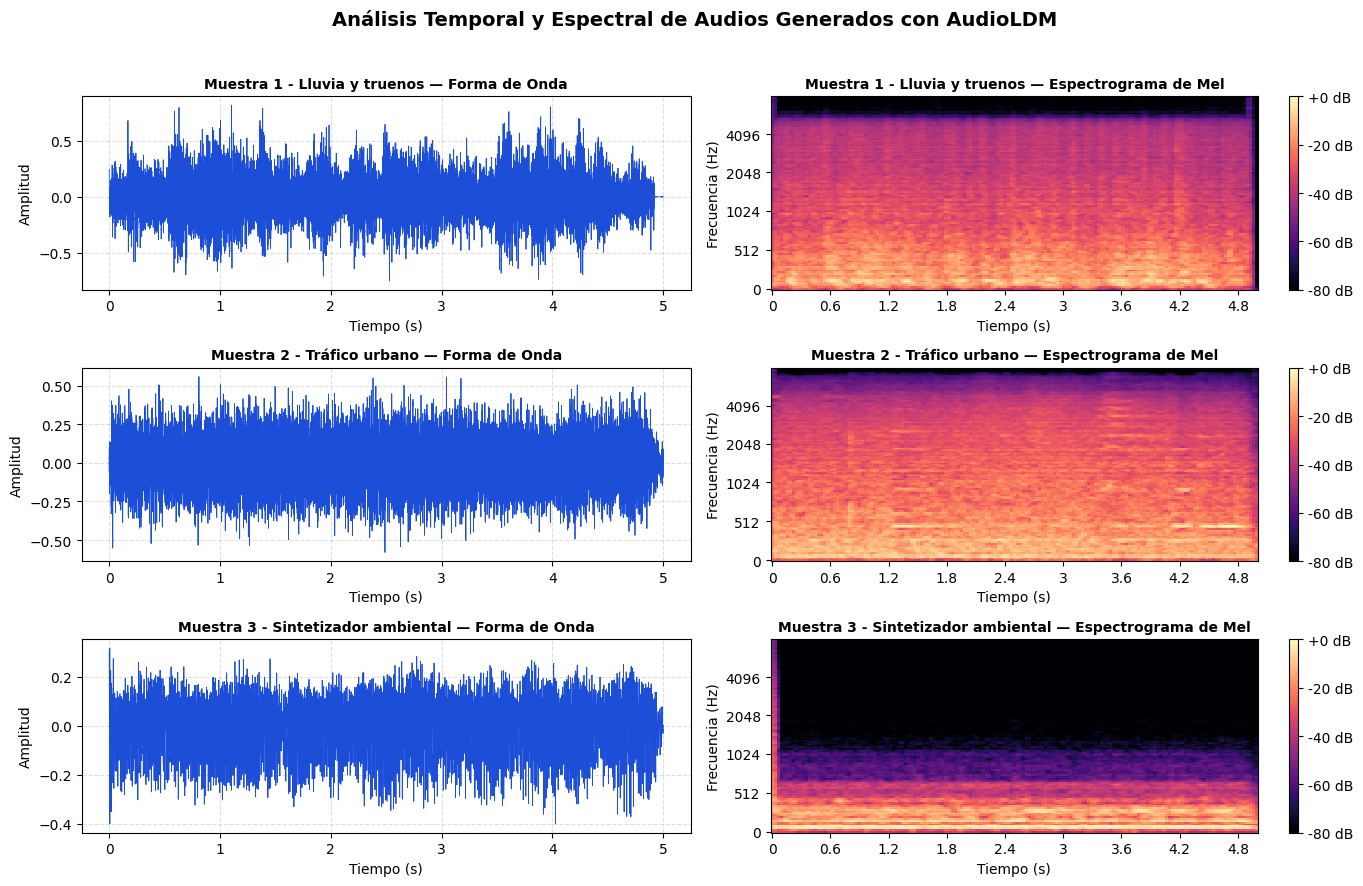


[INFO] Gráfica comparativa guardada en 'resultados_audio/figura1_analisis_audio.png'.
[INFO] Puedes descargarla e insertarla en el recuadro de la Figura 1 del informe Word.


In [1]:



# INSTALACIÓN DE DEPENDENCIAS



import os
import random
import numpy as np
import scipy.io.wavfile as wavfile
import librosa
import librosa.display
import matplotlib.pyplot as plt
import torch
from IPython.display import Audio, display
from diffusers import AudioLDMPipeline

# Fijar semilla aleatoria
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Verificar dispositivo de cómputo
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print(f"[INFO] Dispositivo activo en Google Colab: {device}")

# Carpeta para almacenar los audios .wav
os.makedirs("resultados_audio", exist_ok=True)


# CARGA DEL PIPELINE TEXT-TO-AUDIO

REPO_ID = "cvssp/audioldm-s-full-v2"
print(f"[INFO] Descargando y cargando el modelo '{REPO_ID}'...")

pipe = AudioLDMPipeline.from_pretrained(REPO_ID, torch_dtype=dtype)
pipe = pipe.to(device)
print("[INFO] Modelo AudioLDM cargado correctamente.")


#DEFINICIÓN DE PROMPTS Y SÍNTESIS DE SEÑALES DE AUDIO

prompts_prueba = [
    ("Muestra 1 - Lluvia y truenos", "Heavy rain falling on a wooden roof with distant thunder"),
    ("Muestra 2 - Tráfico urbano", "City street traffic with car horns and footsteps"),
    ("Muestra 3 - Sintetizador ambiental", "Warm analog synthesizer pad playing a calm ambient chord")
]

SAMPLE_RATE = 16000       # Frecuencia de muestreo nativa de AudioLDM (16 kHz)
DURACION_SEG = 5.0        # Duración de cada clip en segundos
PASOS_DIFUSION = 50       # Iteraciones de denoising
GUIDANCE_SCALE = 2.5      # Escala de guía textual (Classifier-Free Guidance)

resultados = []

for idx, (titulo, prompt_texto) in enumerate(prompts_prueba, start=1):
    print("\n" + "=" * 72)
    print(f"Generando {titulo}...")
    print(f"Prompt: '{prompt_texto}'")

    generador = torch.Generator(device=device).manual_seed(SEED + idx)

    # Ejecutar proceso de difusión inversa y decodificación con HiFi-GAN
    salida = pipe(
        prompt=prompt_texto,
        num_inference_steps=PASOS_DIFUSION,
        audio_length_in_s=DURACION_SEG,
        guidance_scale=GUIDANCE_SCALE,
        generator=generador
    )

    audio_array = salida.audios[0]  # Arreglo 1D en float32

    # Guardar archivo .wav en disco
    ruta_wav = f"resultados_audio/muestra_{idx}.wav"
    wavfile.write(ruta_wav, rate=SAMPLE_RATE, data=audio_array)

    # Calcular métricas acústicas objetivas con Librosa y NumPy
    rms_medio = float(np.mean(librosa.feature.rms(y=audio_array)))
    centroide_hz = float(np.mean(librosa.feature.spectral_centroid(y=audio_array, sr=SAMPLE_RATE)))
    zcr_medio = float(np.mean(librosa.feature.zero_crossing_rate(y=audio_array)))

    resultados.append({
        "titulo": titulo,
        "prompt": prompt_texto,
        "audio": audio_array,
        "ruta_wav": ruta_wav,
        "rms": rms_medio,
        "centroide": centroide_hz,
        "zcr": zcr_medio
    })

    print(f"[OK] Guardado en: {ruta_wav}")
    print(f"     Métricas -> RMS: {rms_medio:.4f} | Centroide Espectral: {centroide_hz:.2f} Hz | ZCR: {zcr_medio:.4f}")

    # Mostrar reproductor de audio interactivo en la celda de Colab
    display(Audio(audio_array, rate=SAMPLE_RATE))


#VISUALIZACIÓN DE FORMAS DE ONDA Y ESPECTROGRAMAS DE MEL

fig, axes = plt.subplots(len(resultados), 2, figsize=(14, 9))
fig.suptitle("Análisis Temporal y Espectral de Audios Generados con AudioLDM", fontsize=14, fontweight="bold")

for i, item in enumerate(resultados):
    y = item["audio"]
    tiempo = np.linspace(0, len(y) / SAMPLE_RATE, num=len(y))

    # Columna 1: Forma de onda en el dominio del tiempo
    ax_wave = axes[i, 0]
    ax_wave.plot(tiempo, y, color="#1D4ED8", linewidth=0.6)
    ax_wave.set_title(f"{item['titulo']} — Forma de Onda", fontsize=10, fontweight="bold")
    ax_wave.set_xlabel("Tiempo (s)")
    ax_wave.set_ylabel("Amplitud")
    ax_wave.grid(True, linestyle="--", alpha=0.4)

    # Columna 2: Espectrograma de Mel en decibelios (dB)
    ax_spec = axes[i, 1]
    S = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=128, fmax=8000)
    S_dB = librosa.power_to_db(S, ref=np.max)
    img = librosa.display.specshow(S_dB, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", fmax=8000, ax=ax_spec, cmap="magma")
    ax_spec.set_title(f"{item['titulo']} — Espectrograma de Mel", fontsize=10, fontweight="bold")
    ax_spec.set_xlabel("Tiempo (s)")
    ax_spec.set_ylabel("Frecuencia (Hz)")
    fig.colorbar(img, ax=ax_spec, format="%+2.0f dB")

plt.tight_layout(rect=[0, 0, 1, 0.96])
ruta_grafica = "resultados_audio/figura1_analisis_audio.png"
plt.savefig(ruta_grafica, dpi=300)
plt.show()

print(f"\n[INFO] Gráfica comparativa guardada en '{ruta_grafica}'.")
print("[INFO] Puedes descargarla e insertarla en el recuadro de la Figura 1 del informe Word.")